<a href="https://colab.research.google.com/github/nahdaauliya/PCVK_Ganjil_2026/blob/main/Modul6_PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [3]:
def convolution2d(image, kernel, stride, padding):
    # Menambahkan padding pada gambar
    image_padded = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode='constant',
        constant_values=0
    )

    # Ukuran gambar dan kernel
    image_height, image_width = image_padded.shape
    kernel_height, kernel_width = kernel.shape

    # Menghitung ukuran output
    output_height = ((image_height - kernel_height) // stride) + 1
    output_width = ((image_width - kernel_width) // stride) + 1

    # Membuat matriks output
    output = np.zeros((output_height, output_width))

    # Proses konvolusi
    for i in range(0, output_height):
        for j in range(0, output_width):

            # Menentukan area gambar yang sesuai dengan kernel
            row_start = i * stride
            row_end = row_start + kernel_height

            col_start = j * stride
            col_end = col_start + kernel_width

            region = image_padded[row_start:row_end, col_start:col_end]

            # Perkalian antara region dengan kernel
            output[i, j] = np.sum(region * kernel)

    return output

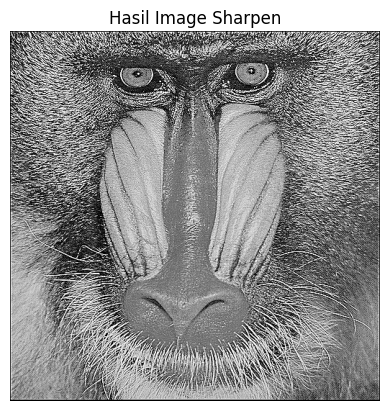

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0,-1,0]])
hasil_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)

hasil_sharpen = np.clip(hasil_sharpen, 0, 255).astype(np.uint8)
plt.imshow(hasil_sharpen, cmap='gray')
plt.title('Hasil Image Sharpen')
plt.axis('off')
plt.show()

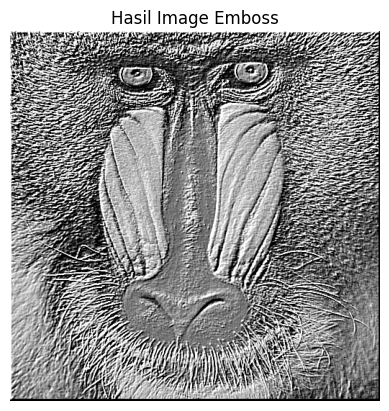

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_emboss = np.array([[-2, -1, 0],
                           [-1, 1, 1],
                           [0,1,2]])
hasil_emboss = convolution2d(img_gray, kernel_emboss, 1, 2)

hasil_emboss = np.clip(hasil_emboss, 0, 255).astype(np.uint8)
plt.imshow(hasil_emboss, cmap='gray')
plt.title('Hasil Image Emboss')
plt.axis('off')
plt.show()

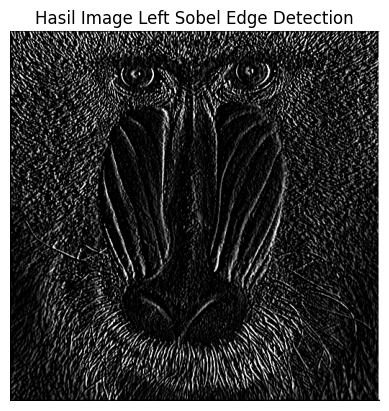

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_LeftSobelEdgeDetection = np.array([[1, 0, -1],
                                          [2, 0, -2],
                                          [1, 0, -1]])
hasil_LeftSobelEdgeDetection = convolution2d(img_gray, kernel_LeftSobelEdgeDetection, 1, 2)

hasil_LeftSobelEdgeDetection = np.clip(hasil_LeftSobelEdgeDetection, 0, 255).astype(np.uint8)
plt.imshow(hasil_LeftSobelEdgeDetection, cmap='gray')
plt.title('Hasil Image Left Sobel Edge Detection')
plt.axis('off')
plt.show()

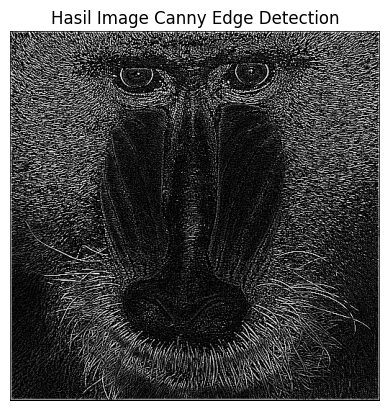

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_CannyEdgeDetection = np.array([[-1, -1, -1],
                                      [-1, 8, -1],
                                      [-1, -1, -1]])
hasil_CannyEdgeDetection = convolution2d(img_gray, kernel_CannyEdgeDetection, 1, 2)

hasil_CannyEdgeDetection = np.clip(hasil_CannyEdgeDetection, 0, 255).astype(np.uint8)
plt.imshow(hasil_CannyEdgeDetection, cmap='gray')
plt.title('Hasil Image Canny Edge Detection')
plt.axis('off')
plt.show()

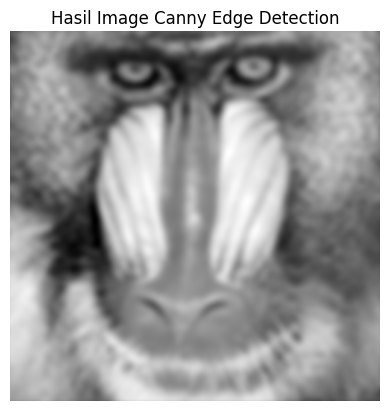

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_size = 21
sigma=math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @gaussian_kernel.transpose()

hasil_blur = convolution2d(img_gray, gauss_kernel, 1, 2)
plt.imshow(hasil_blur, cmap='gray')
plt.title('Hasil Image Canny Edge Detection')
plt.axis('off')
plt.show()

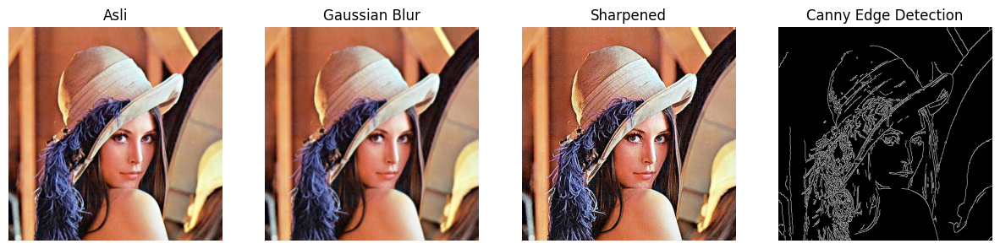

In [ ]:
def show_side_by_side(images, titles,figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2: #grayscale
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else: #color
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

img = cv.imread("/content/drive/MyDrive/PCVK/Images/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

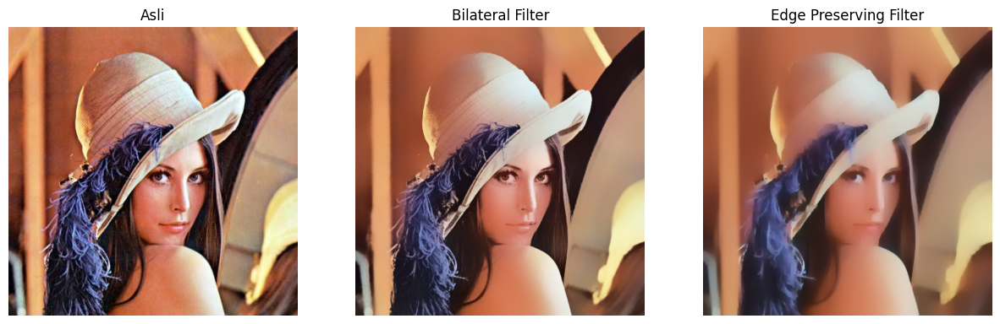

In [4]:
def show_side_by_side(images, titles,figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2: #grayscale
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else: #color
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

img = cv.imread("/content/drive/MyDrive/PCVK/Images/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

bilateral = cv.bilateralFilter(img, 50, 100,100)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)
show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

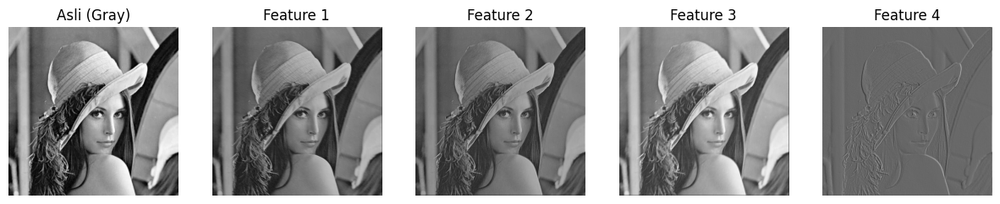

In [12]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(1,4,kernel_size=3, stride=1, padding=1)

  def forward(self, x):
    return self.conv1(x)

model = SimpleCNN()

img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

with torch.no_grad():
  features = model(img_tensor)

feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray]+feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

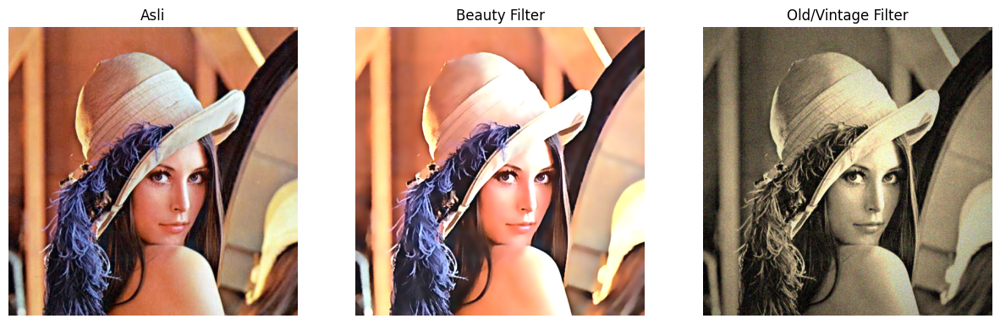

In [16]:
#========================
# 1. Beauty Filter
#========================
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

#Step 2: Unsharp masking(pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

#Step 3: Brightness & contrast
alpha = 1.2 #contrast
beta = 15   #brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

#========================
# 2. Old/Vintage Filter
# Step 1: Sepia tone
#========================
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel/kernel.max()
vignette = np.copy(sepia)
for i in range(3):
  vignette[:,:,i] = vignette[:,:,i] *mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)
show_side_by_side([img, beauty, old_img],
                  ["Asli", "Beauty Filter", "Old/Vintage Filter"])

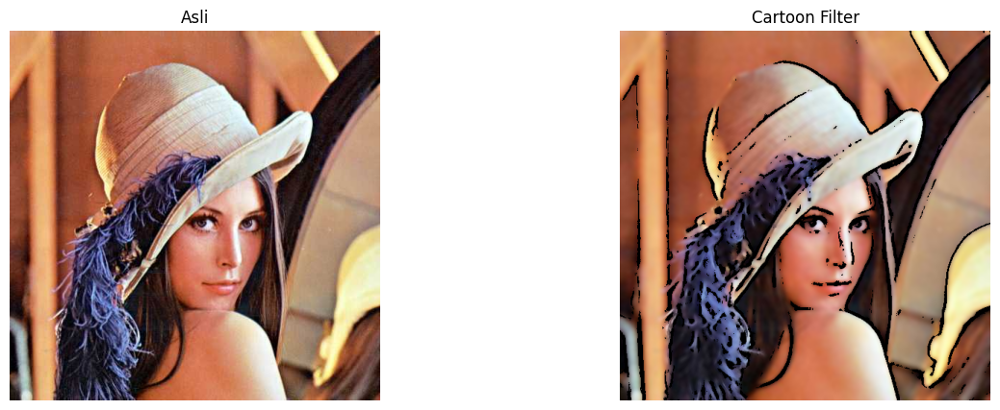

In [6]:
#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi Lebih halus)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9,9)
# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

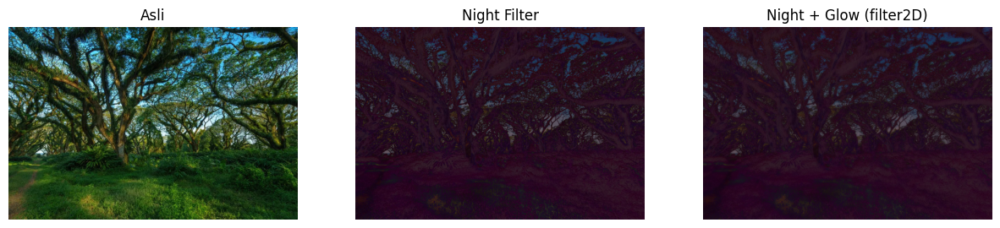

In [8]:
#Night Filter
img = cv.imread("/content/drive/MyDrive/PCVK/Images/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brigthness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

#Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50,0,100)) #BGR
night = cv.addWeighted(night, 0.8,blue_tint, 0.2, 0)

#Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

#Kombinasikan aslo + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)
show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

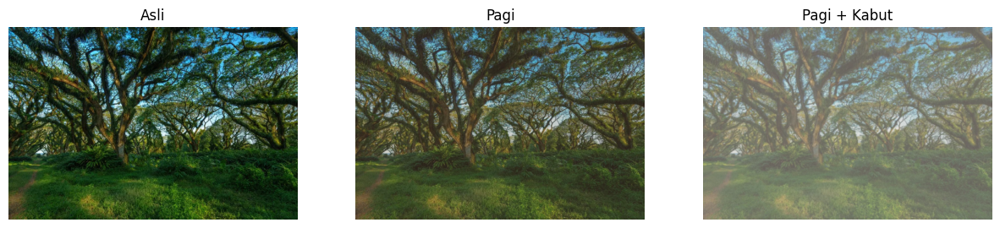

In [9]:
#Filter Suasana pagi dan kabut
#========================
#Step 1: Kurangi kontras & cerahkan
#========================
alpha = 0.9 #contrast
beta = 20 #brigthness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

#========================
#Step 2: Tambahkan warm tone (kemerahan / oranye)
#========================

warm_tint = np.full_like(soft, (40, 70, 120)) #BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

#========================
#Step 3: Tambahkan haze (kabut tipis) dengan filter2D
#========================
#Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3,3)
kernel = kernel @ kernel.T #jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

#Tugas Praktikum

##Analisis

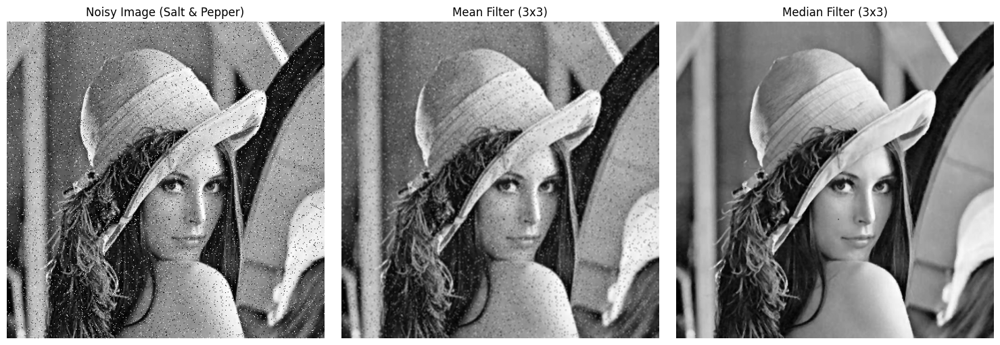

In [10]:
def add_salt_and_pepper_noise(image, prob=0.05):
    noisy_img = np.copy(image)

    random_matrix = np.random.rand(*noisy_img.shape)

    noisy_img[random_matrix < prob / 2] = 0

    noisy_img[random_matrix > 1 - (prob / 2)] = 255
    return noisy_img

img_gray = cv.imread('/content/drive/MyDrive/PCVK/Images (1)/Images/lena.jpg', cv.IMREAD_GRAYSCALE)
img_noisy = add_salt_and_pepper_noise(img_gray, prob=0.05)

mean_filtered = cv.blur(img_noisy, (3, 3))
median_filtered = cv.medianBlur(img_noisy, 3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_noisy, cmap='gray')
axes[0].set_title('Noisy Image (Salt & Pepper)')
axes[1].imshow(mean_filtered, cmap='gray')
axes[1].set_title('Mean Filter (3x3)')
axes[2].imshow(median_filtered, cmap='gray')
axes[2].set_title('Median Filter (3x3)')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Filter median lebih baik dalam menghilangkan noise salt and pepper dibandingkan dengan filter mean. Filter median bekerja dengan mengurutkan seluruh nilai piksel dalam area 3×3, kemudian memilih nilai yang berada tepat di tengah. Karena noise salt and pepper terdiri dari nilai piksel yang sangat tinggi atau sangat rendah, nilai tersebut akan berada di bagian paling ujung setelah diurutkan sehingga dapat diabaikan. Nilai piksel pusat kemudian digantikan dengan nilai piksel tetangga yang sebenarnya, sehingga noise dapat dihilangkan dengan tetap mempertahankan ketajaman tepi gambar (edges).

##Tugas Evaluasi

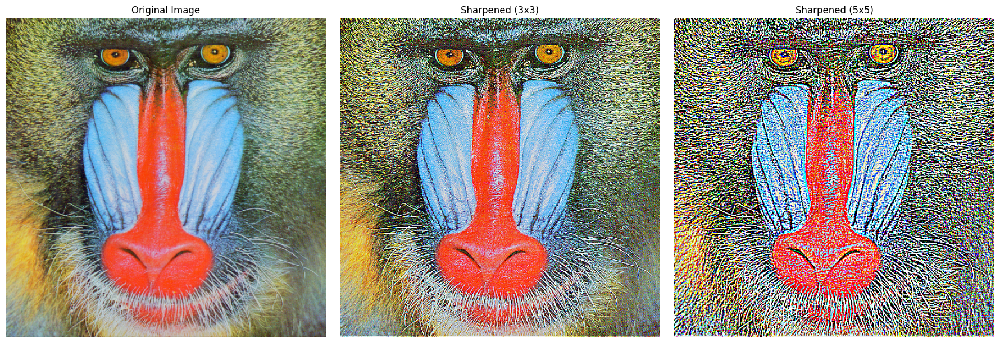

In [11]:
img_color = cv.imread('/content/drive/MyDrive/PCVK/Images (1)/Images/mandrill.tiff')
img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]])

kernel_5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1, -1, -1, -1, -1],
                       [-1, -1, 25, -1, -1],
                       [-1, -1, -1, -1, -1],
                       [-1, -1, -1, -1, -1]])

sharpened_3x3 = cv.filter2D(img_rgb, -1, kernel_3x3)
sharpened_5x5 = cv.filter2D(img_rgb, -1, kernel_5x5)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title('Original Image')
axes[1].imshow(sharpened_3x3)
axes[1].set_title('Sharpened (3x3)')
axes[2].imshow(sharpened_5x5)
axes[2].set_title('Sharpened (5x5)')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Kernel 3×3 merupakan pilihan yang paling optimal untuk penggunaan sehari-hari. Kernel ini memberikan keseimbangan yang baik antara mempertajam tepi gambar yang buram dan mempertahankan kualitas gambar secara keseluruhan tanpa menimbulkan noise berlebihan. Kernel 3×3 mampu meningkatkan kejelasan tepi gambar secara efektif dengan tetap mempertahankan tampilan yang alami dan hanya sedikit meningkatkan noise. Sementara itu, kernel 5×5 mencakup area piksel yang jauh lebih luas sehingga dapat menyebabkan penajaman tepi yang berlebihan (over-sharpening).

##Tugas Kreasi: Filter Kartun Sederhana

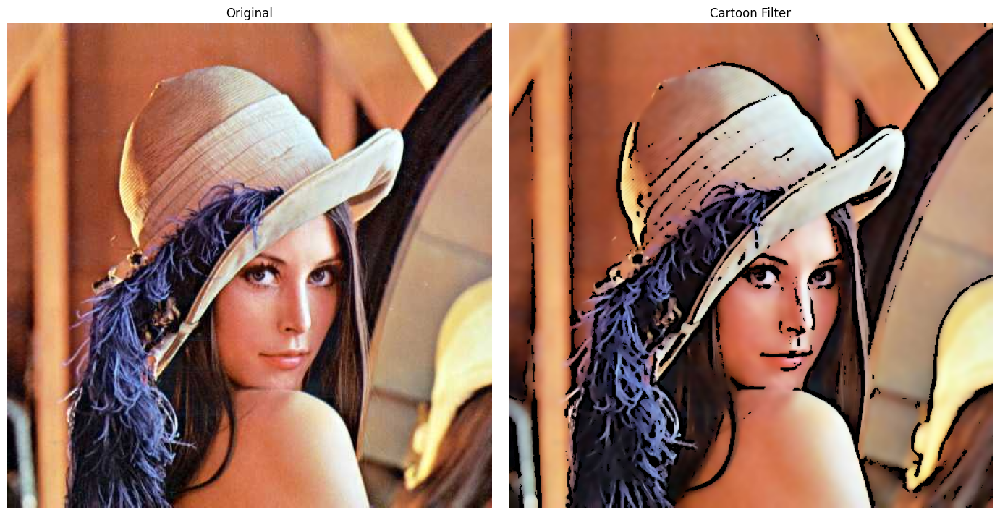

In [12]:
def cartoon(image):
    color_smoothed = cv.bilateralFilter(image, d=9, sigmaColor=75, sigmaSpace=75)

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blurred = cv.medianBlur(gray, 5)

    edges = cv.adaptiveThreshold(gray_blurred, 255,
                                 cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 9)

    edges_color = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
    cartoon_result = cv.bitwise_and(color_smoothed, edges_color)

    return cartoon_result
img_color = cv.imread('/content/drive/MyDrive/PCVK/Images (1)/Images/lena.jpg')
img_cartoon = cartoon(img_color)

original_display = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
cartoon_display = cv.cvtColor(img_cartoon, cv.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(original_display)
axes[0].set_title('Original')
axes[1].imshow(cartoon_display)
axes[1].set_title('Cartoon Filter')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
